# MSI5001 SER

Compare seven untuned models on AESDD: DummyClassifier, KNN, Logistic Regression, 
Random Forest, SVM, MLP and CNN. The six scikit-learn classifiers retain their
default constructor settings (including MLP's 200-iteration limit).
CNN uses two convolution layers, Adam defaults, batch size 32 and 10 epochs.

Run the eight sections in order. Set `FEATURE_SET` in section 4 to `'rich'`
for all 97 acoustic features (default), or `'mfcc'` for 40 MFCC mean/std features
for the scikit-learn models.
CNN uses 64×128 log-mel images. Evaluation reports accuracy and macro F1 for one
approximately 80/20 stratified group random split and LOSO by speaker.
Alternate takes stay together in the random split. LOSO scores pool the predictions
from all held-out speakers. Every model uses the same test recordings.

## 1. Install dependency & import library

Installation is optional when the selected kernel already has the dependencies.
Run installation before imports and restart the kernel after upgrades if required.
For local NVIDIA GPU support, install a CUDA-enabled PyTorch build using the
[official selector](https://pytorch.org/get-started/locally/) in your environment;
skip the installation cell once that environment is ready.

In [66]:
%pip install --upgrade numpy pandas scikit-learn librosa soundfile gdown matplotlib ipython torch

Note: you may need to restart the kernel to use updated packages.


In [67]:
from pathlib import Path
import re, zipfile, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Audio, Markdown
import librosa
import soundfile as sf
import gdown
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold, LeaveOneGroupOut
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

## 2. Load dataset

Choose `local` or `drive`. Local input accepts a WAV directory, ZIP, or folder of ZIPs.
Drive input copies a public folder or dataset ZIP locally without mounting Drive.
The Drive sharing setting must be **Anyone with the link → Viewer**.
This section lists candidate AESDD files; audio validation and cleanup happen in section 3.

In [68]:
SOURCE = 'local'                         # 'local' or 'drive'
LOCAL_PATH = r'./AESDD'                   # WAV directory, ZIP, or folder of ZIPs
DRIVE_URL = 'PASTE_PUBLIC_FILE_OR_FOLDER_URL_HERE'

root = Path(LOCAL_PATH).expanduser().resolve()
if SOURCE == 'drive':
    root = Path('./downloaded_AESDD').resolve()
    root.mkdir(exist_ok=True)
    if '/folders/' in DRIVE_URL:
        downloaded = gdown.download_folder(DRIVE_URL, output=str(root), use_cookies=False)
    else:
        downloaded = gdown.download(DRIVE_URL, output=str(root/'dataset.zip'), use_cookies=False)
    if not downloaded:
        raise RuntimeError('Download failed. Use a public anyone-with-the-link Drive URL.')
elif SOURCE != 'local':
    raise ValueError("SOURCE must be 'local' or 'drive'.")
if not root.exists():
    raise FileNotFoundError(f'Edit LOCAL_PATH: {root}')

def unzip(path):
    destination = path.with_suffix('')
    if not (destination/'.extracted').exists():
        with zipfile.ZipFile(path) as archive:
            if any(not (destination/name).resolve().is_relative_to(destination.resolve())
                   for name in archive.namelist()):
                raise ValueError('Unsafe archive path')
            archive.extractall(destination)
        (destination/'.extracted').touch()
    return destination

if root.is_file():
    root = unzip(root)
for _ in range(3):                       # Also handles ZIPs inside a downloaded folder
    for archive in list(root.rglob('*.zip')):
        unzip(archive)

codes = {'a':'Anger', 'd':'Disgust', 'f':'Fear', 'h':'Happiness', 's':'Sadness'}
pattern = re.compile(r'([adfhs])\s*[_ -]?(\d{1,2})\s*[_ -]?\(\s*(\d+)\s*\)\s*[a-z]*', re.I)
records = []
for path in sorted(root.rglob('*.wav')):
    match = pattern.fullmatch(path.stem)
    if not match or '__MACOSX' in path.parts:
        continue
    emotion, utterance, speaker = match.groups()
    emotion, speaker = emotion.lower(), str(int(speaker))
    records.append({'path':path, 'emotion':codes[emotion], 'speaker':speaker,
                    'group':f'{speaker}_{emotion}_{int(utterance)}'})
if not records:
    raise ValueError('No AESDD WAV filenames found. Check the dataset path and filenames.')
recordings = pd.DataFrame(records)
display(pd.DataFrame([{'Source':SOURCE, 'Dataset folder':str(root),
                       'Candidate recordings':len(recordings)}]))

,Source,Dataset folder,Candidate recordings
0,local,C:\Users\lichow\Dropbox\NUS\MSI5001 Introducti...,605


## 3. Explore and clean dataset

Inspect the candidate counts, then remove byte-identical duplicates and skip
damaged, empty, non-finite or silent WAVs. Silence is checked on the mono signal;
the original samples are cached for preprocessing and playback.
Tables show counts before and after cleanup, removal reasons, speaker/emotion
distribution, and the first five usable recordings. Audio players preview those
five recordings. Playback normalization does not alter the model inputs.

**Cleanup summary**

,Recordings
Before cleanup,605
Removed duplicates,0
Skipped invalid WAVs,1
After cleanup,604


**Removed recordings**

,File,Status,Reason
0,s05 (3).wav,Invalid,Error opening 'C:\\Users\\lichow\\Dropbox\\NUS...


**Recordings per emotion**

,Before cleanup,After cleanup
emotion,,
Anger,121,121
Disgust,122,122
Fear,120,120
Happiness,119,119
Sadness,123,122


**Usable recordings per speaker and emotion**

emotion,Anger,Disgust,Fear,Happiness,Sadness
speaker,,,,,
1,20,20,20,20,20
2,20,20,20,20,20
3,20,20,20,19,19
4,20,20,19,20,20
5,21,22,21,20,23
6,20,20,20,20,20


**Recording duration (seconds)**

,Seconds
mean,4.10
std,1.62
min,0.98
25%,2.90
50%,3.76
75%,4.86
max,12.73


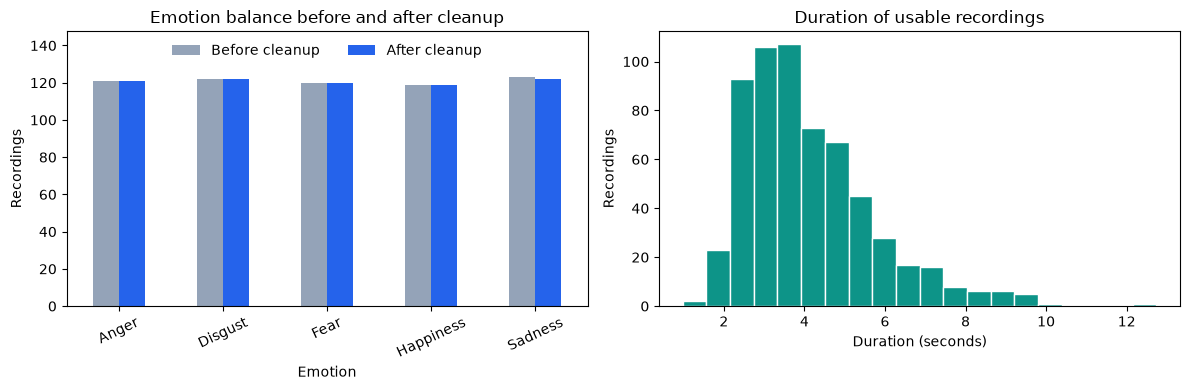

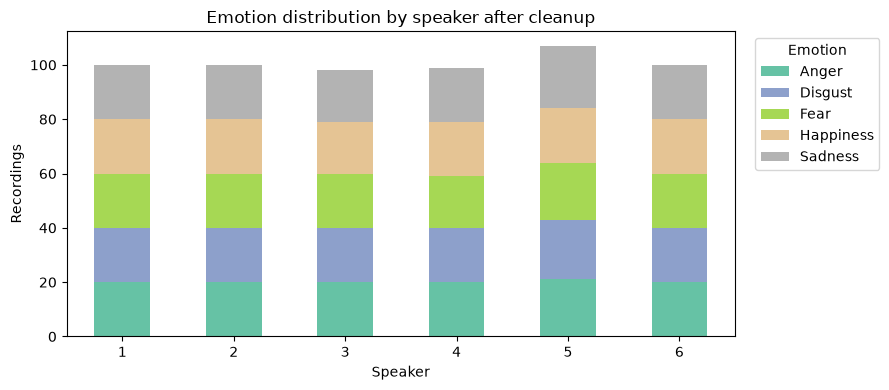

In [69]:
before_counts = recordings.emotion.value_counts().sort_index()
candidate_count = len(recordings)
clean_records, cleanup_log, audio_cache, seen = [], [], {}, set()
for record in recordings.to_dict('records'):
    path = record['path']
    try:
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        if digest in seen:
            cleanup_log.append({'File':path.name, 'Status':'Duplicate',
                                'Reason':'Byte-identical to a retained recording'})
            continue
        audio, sr = sf.read(path, dtype='float32', always_2d=True)
        if not len(audio) or sr <= 0:
            raise ValueError('Empty recording or invalid sample rate')
        if not np.isfinite(audio).all():
            raise ValueError('Non-finite audio samples')
        if np.max(np.abs(audio.mean(axis=1))) < 1e-7:
            raise ValueError('Silent mono signal')
    except (RuntimeError, ValueError, OSError) as error:
        cleanup_log.append({'File':path.name, 'Status':'Invalid', 'Reason':str(error)})
        continue
    clean_records.append({**record, 'duration_s':len(audio)/sr,
                          'sample_rate':sr, 'channels':audio.shape[1]})
    audio_cache[path] = (audio, sr)
    seen.add(digest)
if not clean_records:
    raise ValueError('No usable recordings remain after cleanup.')
recordings = pd.DataFrame(clean_records)
cleanup_log = pd.DataFrame(cleanup_log, columns=['File', 'Status', 'Reason'])
cleanup_summary = pd.DataFrame({
    'Recordings':[candidate_count, (cleanup_log.Status == 'Duplicate').sum(),
                  (cleanup_log.Status == 'Invalid').sum(), len(recordings)]
}, index=['Before cleanup', 'Removed duplicates', 'Skipped invalid WAVs', 'After cleanup'])
display(Markdown('**Cleanup summary**'))
display(cleanup_summary)
if not cleanup_log.empty:
    display(Markdown('**Removed recordings**'))
    display(cleanup_log)

emotion_counts = pd.DataFrame({'Before cleanup':before_counts,
                               'After cleanup':recordings.emotion.value_counts()}).fillna(0).astype(int)
emotion_counts = emotion_counts.sort_index()
speaker_counts = pd.crosstab(recordings.speaker, recordings.emotion)
display(Markdown('**Recordings per emotion**'))
display(emotion_counts)
display(Markdown('**Usable recordings per speaker and emotion**'))
display(speaker_counts)
display(Markdown('**Recording duration (seconds)**'))
display(recordings.duration_s.describe().drop('count').to_frame('Seconds').round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
emotion_counts.plot.bar(ax=axes[0], color=['#94a3b8', '#2563eb'], rot=25)
axes[0].set(title='Emotion balance before and after cleanup', xlabel='Emotion', ylabel='Recordings')
axes[0].set_ylim(0, emotion_counts.to_numpy().max()*1.2)
axes[0].legend(loc='upper center', ncol=2, frameon=False)
recordings.duration_s.plot.hist(ax=axes[1], bins=20, color='#0d9488', edgecolor='white')
axes[1].set(title='Duration of usable recordings', xlabel='Duration (seconds)', ylabel='Recordings')
fig.tight_layout()
plt.show()

ax = speaker_counts.plot.bar(stacked=True, figsize=(9, 4), colormap='Set2', rot=0)
ax.set(title='Emotion distribution by speaker after cleanup', xlabel='Speaker', ylabel='Recordings')
ax.legend(title='Emotion', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.figure.tight_layout()
plt.show()


In [70]:
emotion_samples = (
    recordings.groupby('emotion')
    .sample(n=1)
    .sort_values('emotion')
    .copy()
)

emotion_samples['file'] = emotion_samples.path.map(lambda path: path.name)

display(Markdown('**One random recording per emotion**'))
display(
    emotion_samples[['file', 'emotion', 'speaker', 'duration_s', 'sample_rate', 'channels']]
    .reset_index(drop=True)
    .round({'duration_s': 2})
)

for i, record in enumerate(emotion_samples.itertuples(index=False), start=1):
    display(Markdown(
        f'**{i}. {record.path.name}** — {record.emotion}, speaker {record.speaker}'
    ))
    audio, sr = audio_cache[record.path]
    display(Audio(data=audio.T, rate=sr))

**One random recording per emotion**

,file,emotion,speaker,duration_s,sample_rate,channels
0,a08 (3).wav,Anger,3,3.10,44100,1
1,d02 (5).wav,Disgust,5,7.80,44100,1
2,f01 (6).wav,Fear,6,6.12,44100,1
3,h03 (6).wav,Happiness,6,9.53,44100,1
4,s10 (3).wav,Sadness,3,3.85,44100,1


**1. a08 (3).wav** — Anger, speaker 3

**2. d02 (5).wav** — Disgust, speaker 5

**3. f01 (6).wav** — Fear, speaker 6

**4. h03 (6).wav** — Happiness, speaker 6

**5. s10 (3).wav** — Sadness, speaker 3

## 4. Data preprocessing

Convert to mono and resample to 16 kHz. Choose `FEATURE_SET = 'rich'` (default)
for **97 predefined acoustic features**, or `FEATURE_SET = 'mfcc'` for only the
**40 MFCC mean/std features**. The table describes the complete rich set:

| Family | Summary statistics | Count |
| --- | --- | ---: |
| MFCC | Mean/std of 20 coefficients | 40 |
| Pitch | Voiced F0 mean, std, P5, P95; P5–P95 range in semitones | 5 |
| Energy | Mean, std, P5, P95 of active-frame RMS level in dBFS | 4 |
| Spectral shape | Centroid, bandwidth and 85% roll-off mean/std | 6 |
| Timing | Duration, internal pause ratio, pauses per second, voiced-frame ratio | 4 |
| Zero-crossing rate | Mean/std | 2 |
| Spectral flatness | Mean/std | 2 |
| Delta MFCC | Std of the first-order delta of each of 20 MFCCs | 20 |
| Spectral contrast | Mean/std in each of 7 frequency bands | 14 |
| **Total** | | **97** |

Pitch uses pYIN over a fixed 50–600 Hz range. Only finite, voiced estimates
contribute; all five pitch statistics are zero when none are detected.
The semitone range is `12 * log2(P95 / P5)`.

Energy/timing use 25 ms RMS windows with a 10 ms hop. A low-energy frame is more
than 30 dB below that clip's maximum frame RMS level. Internal low-energy runs
lasting at least 150 ms count as pause proxies; leading/trailing silence is excluded.
Pause duration and count are divided by the full clip duration. Energy statistics
use active frames. Voiced ratio is the fraction of pYIN frames flagged as voiced.
These are fixed, per-recording rules; RMS dBFS is a digital level, not calibrated
physical loudness. Equal peak levels do not imply equal RMS levels.

ZCR describes waveform sign changes; flatness describes noise-like versus tonal
spectra. First-order delta MFCCs describe changes over time: use a 9-frame window
with nearest-edge padding and retain each coefficient's standard deviation.
Spectral contrast describes spectral peaks versus valleys in 7 bands (`n_bands=6`).
These four additions are summarised over the whole recording, including quiet frames.
Their emotional relevance is learned jointly with the other features; no single
feature determines an emotion. See the README for interpretation and limitations.

Jitter/shimmer are omitted because they need reliable vocal-cycle analysis.
Onset rate is omitted because it is not a direct speaking-rate measurement.
An extra energy-range feature is omitted because P5/P95 already describe its spread.

Re-run sections 4–8 after changing the selector. MFCC mode skips extraction of
the other feature families. CNN retains its 64×128 log-mel images in both modes. Model settings are unchanged. Learned scaling
remains in section 6; no dataset-wide statistics are fitted during feature extraction.

In [ ]:
FEATURE_SET = 'rich' # 'rich': 97 features; 'mfcc': 40 features
if FEATURE_SET not in {'rich', 'mfcc'}:
    raise ValueError("FEATURE_SET must be 'rich' or 'mfcc'.")
feature_names = [f'mfcc_{i:02d}_{stat}' for stat in ['mean', 'std'] for i in range(20)]
if FEATURE_SET == 'rich':
    feature_names += [f'pitch_hz_{stat}' for stat in ['mean', 'std', 'p05', 'p95']]
    feature_names += ['pitch_range_semitones']
    feature_names += [f'rms_dbfs_{stat}' for stat in ['mean', 'std', 'p05', 'p95']]
    feature_names += [f'{name}_{stat}' for name in
                      ['spectral_centroid_hz', 'spectral_bandwidth_hz', 'spectral_rolloff_hz']
                      for stat in ['mean', 'std']]
    feature_names += ['duration_s', 'pause_ratio', 'pauses_per_second', 'voiced_ratio']
    feature_names += [f'{name}_{stat}' for name in ['zcr', 'spectral_flatness']
                      for stat in ['mean', 'std']]
    feature_names += [f'delta_mfcc_{i:02d}_std' for i in range(20)]
    feature_names += [f'spectral_contrast_band_{band}_{stat}' for band in range(7)
                      for stat in ['mean', 'std']]

def extract_ml_features(audio, feature_set=FEATURE_SET):
    mfcc = librosa.feature.mfcc(y=audio, sr=16000, n_mfcc=20)
    values = np.r_[mfcc.mean(axis=1), mfcc.std(axis=1)]
    if feature_set == 'mfcc':
        return values
    f0, voiced, _ = librosa.pyin(audio, fmin=50, fmax=600, sr=16000)
    pitch = f0[voiced & np.isfinite(f0)]
    pitch_stats = np.zeros(5)
    if pitch.size:
        p05, p95 = np.percentile(pitch, [5, 95])
        pitch_stats = [pitch.mean(), pitch.std(), p05, p95, 12*np.log2(p95/p05)]

    # Active-frame RMS statistics and explicitly defined low-energy pause proxies.
    rms = librosa.feature.rms(y=audio, frame_length=400, hop_length=160)[0]
    rms_db = 20*np.log10(np.maximum(rms, 1e-8))
    active = rms_db >= rms_db.max()-30
    levels = rms_db[active]
    energy_stats = np.r_[levels.mean(), levels.std(), np.percentile(levels, [5,95])]
    internal_silence = ~active
    active_frames = np.flatnonzero(active)
    internal_silence[:active_frames[0]] = False
    internal_silence[active_frames[-1]+1:] = False
    edges = np.diff(np.r_[0, internal_silence.astype(int), 0])
    starts, ends = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)
    duration = len(audio)/16000
    pause_lengths = np.minimum(ends*0.01, duration)-np.minimum(starts*0.01, duration)
    pause_lengths = pause_lengths[pause_lengths >= 0.15]

    spectral_tracks = [
        librosa.feature.spectral_centroid(y=audio, sr=16000)[0],
        librosa.feature.spectral_bandwidth(y=audio, sr=16000)[0],
        librosa.feature.spectral_rolloff(y=audio, sr=16000, roll_percent=0.85)[0]
    ]
    spectral_stats = np.array([(track.mean(), track.std()) for track in spectral_tracks]).ravel()
    timing = [duration, pause_lengths.sum()/duration, len(pause_lengths)/duration, voiced.mean()]
    values = np.r_[values, pitch_stats, energy_stats, spectral_stats, timing]
    zcr = librosa.feature.zero_crossing_rate(audio)[0]
    flatness = librosa.feature.spectral_flatness(y=audio)[0]
    delta_mfcc = librosa.feature.delta(mfcc, width=9, order=1, mode='nearest')
    contrast = librosa.feature.spectral_contrast(y=audio, sr=16000, n_bands=6)
    contrast_stats = np.array([(band.mean(), band.std()) for band in contrast]).ravel()
    return np.r_[values, zcr.mean(), zcr.std(), flatness.mean(), flatness.std(),
                 delta_mfcc.std(axis=1), contrast_stats]

features, images = [], []
for record in recordings.to_dict('records'):
    audio, sr = audio_cache[record['path']]
    audio = librosa.resample(audio.mean(axis=1), orig_sr=sr, target_sr=16000)
    mel = librosa.feature.melspectrogram(y=audio, sr=16000, n_mels=64)
    mel = torch.tensor(librosa.power_to_db(mel), dtype=torch.float32)[None, None]
    image = nn.functional.interpolate(mel, size=(64,128), mode='bilinear', align_corners=False)[0].numpy()
    if not features:
        example_audio = audio
    features.append(extract_ml_features(audio))
    images.append(image)
metadata = recordings.copy()
X, Z = np.asarray(features), np.asarray(images)
if X.shape[1] != len(feature_names) or not np.isfinite(X).all():
    raise ValueError('Acoustic feature count mismatch or non-finite values found.')
encoder = LabelEncoder()
y = encoder.fit_transform(metadata.emotion)
display(pd.DataFrame([
    {'Input':f'Acoustic features ({FEATURE_SET})', 'Shape':str(X.shape), 'Used by':'Six scikit-learn models'},
    {'Input':'Log-mel images', 'Shape':str(Z.shape), 'Used by':'CNN'},
    {'Input':'Emotion labels', 'Shape':str(y.shape), 'Used by':'All seven models'}
]))
display(pd.DataFrame({'Label':np.arange(len(encoder.classes_)), 'Emotion':encoder.classes_}))

feature_families = [('MFCC', 'Mean/std of 20 coefficients', 40)]
if FEATURE_SET == 'rich':
    feature_families += [
        ('Pitch', 'Mean/std/P5/P95; semitone range', 5),
        ('Energy', 'Active-frame RMS dBFS mean/std/P5/P95', 4),
        ('Spectral shape', 'Centroid/bandwidth/roll-off mean/std', 6),
        ('Timing', 'Duration/pause ratio/pause rate/voiced ratio', 4),
        ('Zero-crossing rate', 'Mean/std', 2),
        ('Spectral flatness', 'Mean/std', 2),
        ('Delta MFCC', 'Std of 20 first-order delta coefficients', 20),
        ('Spectral contrast', 'Mean/std of 7 bands', 14)
    ]
display(pd.DataFrame(feature_families, columns=['Feature family', 'Statistics', 'Feature count']))

,Input,Shape,Used by
0,Acoustic features (rich),"(604, 97)",Six scikit-learn models
1,Log-mel images,"(604, 1, 64, 128)",CNN
2,Emotion labels,"(604,)",All seven models


,Label,Emotion
0,0,Anger
1,1,Disgust
2,2,Fear
3,3,Happiness
4,4,Sadness


,Feature family,Statistics,Feature count
0,MFCC,Mean/std of 20 coefficients,40
1,Pitch,Mean/std/P5/P95; semitone range,5
2,Energy,Active-frame RMS dBFS mean/std/P5/P95,4
3,Spectral shape,Centroid/bandwidth/roll-off mean/std,6
4,Timing,Duration/pause ratio/pause rate/voiced ratio,4
5,Zero-crossing rate,Mean/std,2
6,Spectral flatness,Mean/std,2
7,Delta MFCC,Std of 20 first-order delta coefficients,20
8,Spectral contrast,Mean/std of 7 bands,14


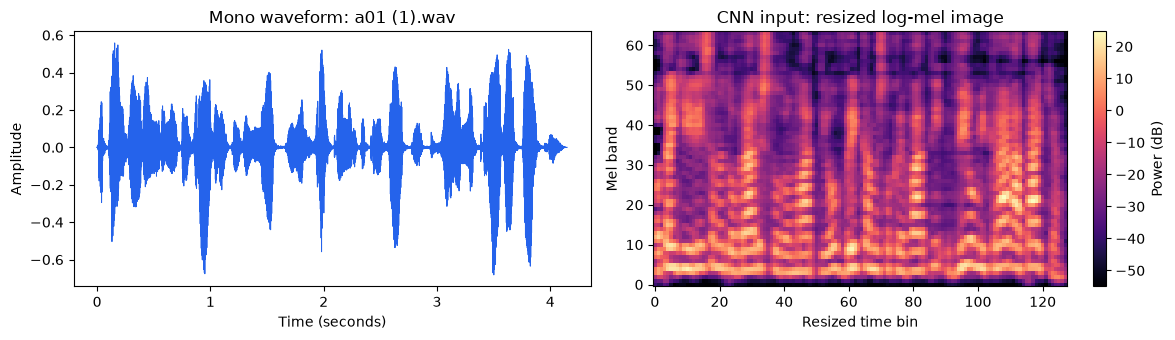

In [72]:
example = metadata.iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(np.arange(len(example_audio))/16000, example_audio, color='#2563eb', linewidth=0.7)
axes[0].set(title=f'Mono waveform: {example.path.name}', xlabel='Time (seconds)', ylabel='Amplitude')
image_plot = axes[1].imshow(Z[0, 0], origin='lower', aspect='auto', cmap='magma')
axes[1].set(title='CNN input: resized log-mel image', xlabel='Resized time bin', ylabel='Mel band')
fig.colorbar(image_plot, ax=axes[1], label='Power (dB)')
fig.tight_layout()
plt.show()

## 5. Train test split (random & LOSO)

Random: use the first fold of a shuffled five-fold stratified group split, keeping
alternate takes of the same speaker/emotion/utterance together.
LOSO: hold out one complete speaker at a time. LOSO follows speaker boundaries;
it does not stratify or move recordings between speakers.

In [73]:
train, test = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
                   .split(X, y, groups=metadata.group))
splits = [('Random', train, test)]
splits += [('LOSO', tr, te) for tr, te in LeaveOneGroupOut().split(X, y, metadata.speaker)]
split_summary = pd.DataFrame([
    {'Split':('Random' if setting == 'Random' else 'LOSO: speaker '+metadata.speaker.iloc[test].iloc[0]),
     'Train':len(train), 'Test':len(test),
     'Test speakers':','.join(metadata.speaker.iloc[test].unique())}
    for setting, train, test in splits
])
split_summary.index = pd.RangeIndex(1, len(split_summary)+1, name='Fold')
display(split_summary)
random_train, random_test = splits[0][1:]
random_class_counts = pd.DataFrame({
    'Train':np.bincount(y[random_train], minlength=len(encoder.classes_)),
    'Test':np.bincount(y[random_test], minlength=len(encoder.classes_))
}, index=pd.Index(encoder.classes_, name='Emotion'))
display(Markdown('**Emotion counts in the random split**'))
display(random_class_counts)

,Split,Train,Test,Test speakers
Fold,,,,
1,Random,483,121,"3,5,2,4,1,6"
2,LOSO: speaker 1,504,100,1
3,LOSO: speaker 2,504,100,2
4,LOSO: speaker 3,506,98,3
5,LOSO: speaker 4,505,99,4
6,LOSO: speaker 5,497,107,5
7,LOSO: speaker 6,504,100,6


**Emotion counts in the random split**

,Train,Test
Emotion,,
Anger,97,24
Disgust,98,24
Fear,96,24
Happiness,95,24
Sadness,97,25


## 6. Feature scaling

Fit a fresh StandardScaler on each fold's **training acoustic features** and use it to
transform that fold's training and test features. Normalize CNN images using one
global mean and standard deviation computed from that fold's **training images**.
Test recordings never contribute to fitted scaling statistics.

The table has one row per independently scaled split: one random split plus
one LOSO split per speaker. Training-image mean/std should be approximately 0/1
after normalization; test data is transformed using those same training statistics.

In [74]:
scaled_splits = []
for split_name, (setting, train, test) in zip(split_summary.Split, splits):
    scaler = StandardScaler().fit(X[train])
    mean, std = Z[train].mean(), max(float(Z[train].std()), 1e-8)
    scaled_splits.append({
        'name':split_name, 'setting':setting, 'train':train, 'test':test,
        'X_train':scaler.transform(X[train]), 'X_test':scaler.transform(X[test]),
        'Z_train':(Z[train]-mean)/std, 'Z_test':(Z[test]-mean)/std,
        'y_train':y[train], 'y_test':y[test]
    })
display(pd.DataFrame([
    {'Split':fold['name'], 'Train clips':len(fold['train']), 'Test clips':len(fold['test']),
     'Acoustic features':fold['X_train'].shape[1],
     'CNN train mean':float(fold['Z_train'].mean()),
     'CNN train std':float(fold['Z_train'].std())}
    for fold in scaled_splits
]).set_index('Split').round(4))

,Train clips,Test clips,Acoustic features,CNN train mean,CNN train std
Split,,,,,
Random,483,121,97,0.0,1.0
LOSO: speaker 1,504,100,97,-0.0,1.0
LOSO: speaker 2,504,100,97,0.0,1.0
LOSO: speaker 3,506,98,97,-0.0,1.0
LOSO: speaker 4,505,99,97,-0.0,1.0
LOSO: speaker 5,497,107,97,0.0,1.0
LOSO: speaker 6,504,100,97,0.0,1.0


## 7. Model training

Train fresh instances of all seven models for every split. Only training arrays
are passed into fitting. CNN uses CUDA automatically when available; the six
scikit-learn models use CPU. No hyperparameter tuning or early stopping is used.
Convergence warnings remain visible for models using their default iteration limit.

In [75]:
EPOCHS, BATCH_SIZE = 10, 32
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
display(pd.DataFrame([{
    'CNN device':str(DEVICE), 'GPU':torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'Not used',
    'PyTorch':torch.__version__, 'Epochs':EPOCHS, 'Batch size':BATCH_SIZE
}]))
models = {'DummyClassifier':DummyClassifier(), 'KNN':KNeighborsClassifier(), 'Logistic Regression':LogisticRegression(),
          'Random Forest':RandomForestClassifier(), 'SVM':SVC(), 'MLP':MLPClassifier()}

def train_cnn(images, labels):
    torch.manual_seed(42)
    inputs = torch.tensor(images)
    targets = torch.tensor(labels, dtype=torch.long)
    loader = DataLoader(TensorDataset(inputs, targets), batch_size=BATCH_SIZE, shuffle=True)
    model = nn.Sequential(
        nn.Conv2d(1,16,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(32,len(encoder.classes_))
    ).to(DEVICE)
    optimizer, loss_fn = torch.optim.Adam(model.parameters()), nn.CrossEntropyLoss()
    for _ in range(EPOCHS):
        model.train()
        for batch, labels in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(batch.to(DEVICE)), labels.to(DEVICE))
            loss.backward()
            optimizer.step()
    return model

trained_splits = []
for fold in scaled_splits:
    fitted = {}
    for name, estimator in models.items():
        np.random.seed(42)
        fitted[name] = clone(estimator).fit(fold['X_train'], fold['y_train'])
    fitted['CNN'] = train_cnn(fold['Z_train'], fold['y_train'])
    trained_splits.append(fitted)
display(pd.DataFrame([
    {'Split':fold['name'], 'Trained models':len(fitted), 'Status':'Complete'}
    for fold, fitted in zip(scaled_splits, trained_splits)
]))

,CNN device,GPU,PyTorch,Epochs,Batch size
0,cuda,NVIDIA RTX PRO 500 Blackwell Generation Laptop...,2.14.1+cu130,10,32


c:\Users\lichow\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\lichow\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\lichow\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptro

,Split,Trained models,Status
0,Random,7,Complete
1,LOSO: speaker 1,7,Complete
2,LOSO: speaker 2,7,Complete
3,LOSO: speaker 3,7,Complete
4,LOSO: speaker 4,7,Complete
5,LOSO: speaker 5,7,Complete
6,LOSO: speaker 6,7,Complete


## 8. Model prediction and evaluation

Predict on held-out test arrays after training. Report accuracy and macro F1 for
the random split and pooled LOSO predictions, using all five emotion labels.

Accuracy is displayed as a percentage; macro F1 is displayed from 0 to 1.
The two charts compare random-split and pooled LOSO performance for all models.

In [76]:
predictions = []
for fold, fitted in zip(scaled_splits, trained_splits):
    for name, model in fitted.items():
        if name == 'CNN':
            model.eval()
            with torch.no_grad():
                predicted = np.concatenate([
                    model(torch.tensor(fold['Z_test'][i:i+64]).to(DEVICE))
                    .argmax(1).cpu().numpy() for i in range(0,len(fold['Z_test']),64)
                ])
        else:
            predicted = model.predict(fold['X_test'])
        predictions.append((fold['setting'], name, fold['y_test'], predicted))

results = []
for name in [*models, 'CNN']:
    row = {'Model':name}
    for setting in ['Random', 'LOSO']:
        selected = [p for p in predictions if p[0]==setting and p[1]==name]
        actual = np.concatenate([p[2] for p in selected])
        predicted = np.concatenate([p[3] for p in selected])
        row[f'{setting} accuracy'] = accuracy_score(actual, predicted)
        row[f'{setting} macro F1'] = f1_score(actual, predicted, average='macro',
                                            labels=np.arange(len(encoder.classes_)), zero_division=0)
    results.append(row)
summary = pd.DataFrame(results).set_index('Model')
display(summary.style.format({
    'Random accuracy':'{:.1%}', 'Random macro F1':'{:.3f}',
    'LOSO accuracy':'{:.1%}', 'LOSO macro F1':'{:.3f}'
}).set_caption(f'Seven-model comparison — {FEATURE_SET} baseline ({X.shape[1]} features), accuracy and macro F1'))

,Random accuracy,Random macro F1,LOSO accuracy,LOSO macro F1
Model,,,,
DummyClassifier,19.8%,0.066,19.9%,0.133
KNN,60.3%,0.591,42.4%,0.403
Logistic Regression,78.5%,0.781,47.2%,0.456
Random Forest,71.9%,0.710,41.7%,0.401
SVM,74.4%,0.739,43.9%,0.429
MLP,80.2%,0.798,47.4%,0.453
CNN,29.8%,0.239,28.8%,0.235


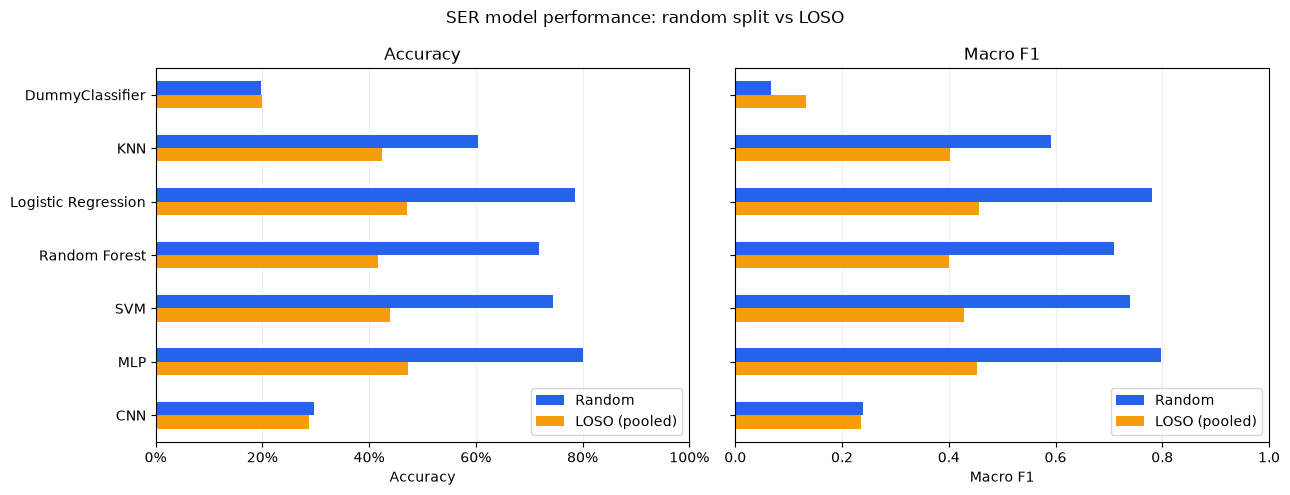

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, metric, columns in zip(axes, ['Accuracy', 'Macro F1'],
        [['Random accuracy', 'LOSO accuracy'], ['Random macro F1', 'LOSO macro F1']]):
    values = summary[columns].copy()
    values.columns = ['Random', 'LOSO (pooled)']
    values.plot.barh(ax=ax, color=['#2563eb', '#f59e0b'])
    ax.set(title=metric, xlabel=metric, ylabel='', xlim=(0, 1))
    ax.grid(axis='x', alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(loc='lower right')
axes[0].invert_yaxis()
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle('SER model performance: random split vs LOSO')
fig.tight_layout()
plt.show()